In [1]:
%store -r

In [2]:
### load libraries

### folder/file management
import os
import pathlib

### tabular data
import pandas as pd

### handle geospatial vector data
import geopandas as gpd

In [3]:
# subset Shirley Chisholm State Park from the New York State Parks shapefile
SCSP_gdf = NYSParks_gdf.loc[NYSParks_gdf.Name == "Shirley Chisholm"].dissolve()
SCSP_gdf

,geometry,OBJECTID,UID,Name,Category,Label,Descriptio,Region,County,Source,...,created_us,created_da,last_edite,last_edi_1,GlobalID,Shape__Are,Shape__Len,FacilityAb,RegionLabe,DrupalID
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,NYS.Parks.Admin,1661261121661,Rebecca.Newell@parks.ny.gov_nysparks,1773416839889,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None


In [4]:
### join the gbif observations to the Shirley Chisholm State Park polygon
gbif_scsp_gdf = (
    SCSP_gdf
       
    ### match the CRS of the gbif data and the ecoregions
    .to_crs(gbif_gdf.crs)

    ### find ecoregion for each observation
    .sjoin(
        gbif_gdf,
        how = 'inner', 
        predicate = 'contains')

   )

### check it out
gbif_scsp_gdf

,geometry,OBJECTID,UID,Name,Category,Label,Descriptio,Region,County,Source,...,GlobalID,Shape__Are,Shape__Len,FacilityAb,RegionLabe,DrupalID,index_right,year,month,individualCount
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,3989,2023,11,1.0
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,3595,2023,10,3.0
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,5722,2021,1,1.0
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,436,2023,10,12.0
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,1058,2025,10,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,2016,2025,4,2.0
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,5890,2021,7,1.0
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,6097,2021,11,16.0
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,6223,2021,10,10.0


<Axes: >

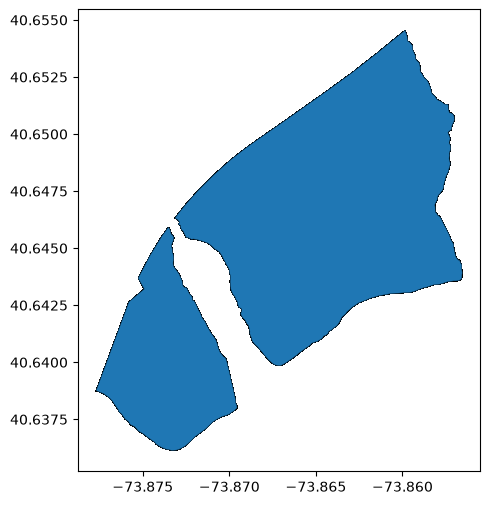

In [5]:
gbif_scsp_gdf.plot(figsize = (10, 6), edgecolor = "black", linewidth = 0.2)
# plt.show()

In [6]:
### Extract breeding months, June, July, August
### Since it is a geodataframe rather than dataframe use .isin instead of ==
breeding_gdf = gbif_scsp_gdf[gbif_scsp_gdf['month'].isin([6, 7, 8])]
breeding_gdf

,geometry,OBJECTID,UID,Name,Category,Label,Descriptio,Region,County,Source,...,GlobalID,Shape__Are,Shape__Len,FacilityAb,RegionLabe,DrupalID,index_right,year,month,individualCount
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,5716,2021,7,1.0
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,5474,2022,8,2.0
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,5961,2021,6,2.0
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,6266,2021,6,1.0
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,1118,2021,7,4.0
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,1125,2022,6,15.0
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,4681,2022,8,2.0
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,2239,2021,7,9.0
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,4960,2022,7,1.0
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,186,2021,7,1.0


In [7]:
### making interactive plots of tabular and vector data
import hvplot.pandas

### customize the dynamic plot
import panel as pn

### make dynamic plot with geodataframe
import holoviews as hv

import matplotlib.pyplot as plt

In [8]:
### Convert breeding to dataframe for plotting purposes
breeding_df = pd.DataFrame(breeding_gdf.drop(columns="geometry"))
breeding_df

,OBJECTID,UID,Name,Category,Label,Descriptio,Region,County,Source,Original,...,GlobalID,Shape__Are,Shape__Len,FacilityAb,RegionLabe,DrupalID,index_right,year,month,individualCount
0,1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,2019,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,5716,2021,7,1.0
0,1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,2019,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,5474,2022,8,2.0
0,1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,2019,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,5961,2021,6,2.0
0,1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,2019,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,6266,2021,6,1.0
0,1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,2019,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,1118,2021,7,4.0
0,1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,2019,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,1125,2022,6,15.0
0,1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,2019,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,4681,2022,8,2.0
0,1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,2019,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,2239,2021,7,9.0
0,1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,2019,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,4960,2022,7,1.0
0,1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,2019,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,186,2021,7,1.0


<Axes: title={'center': 'Savannah Sparrow (Passerculus sandwichensis) counts during breeding season'}, xlabel='Year', ylabel='Number of individuals'>

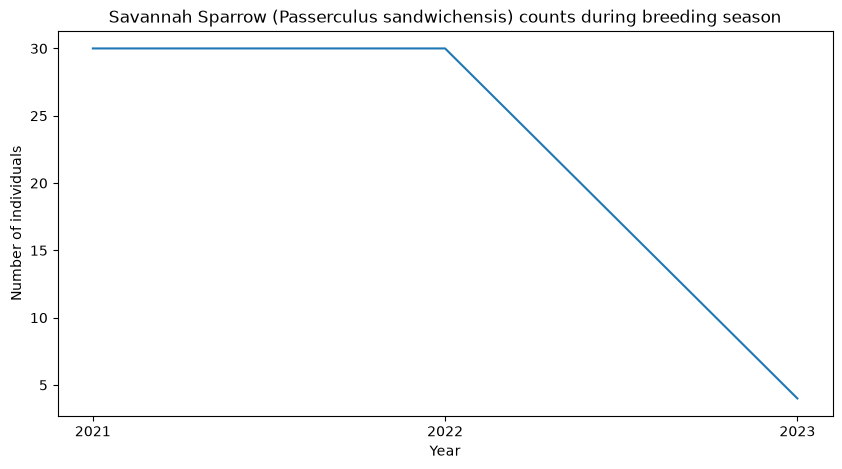

In [9]:
### Plot sparrow count progression during breeding seasons 2021 - 2025
# gdf.sort_values("Year").hvplot.line(
#     x="Year", 
#     y="Number of individuals", 
#     by="site_id",  # <-- Replace with your location/transect column name
#     title="Savannah Sparrow counts by site"
# )
# breeding_df.plot(
#     legend = False,
#     x = "year", 
#     y = "individualCount",
#     xlabel = 'Year',
#     ylabel = 'Number of individuals',
#     figsize = (10, 5),
#     title = "Savannah Sparrow (Passerculus sandwichensis) counts during breeding season"    
# )

### years were displaying as float fractions. Fix from Google AI
years = sorted(breeding_df["year"].unique())

(
    breeding_df
    .groupby("year")["individualCount"]
    .sum()  # or .mean()
    .plot(
        legend=False,
        xticks = years,
        xlabel="Year",
        ylabel="Number of individuals",
        figsize=(10, 5),
        title="Savannah Sparrow (Passerculus sandwichensis) counts during breeding season"
    )
)


In [10]:
### Why does it end at 2023?
breeding_df[breeding_df["year"].isin([2024, 2025])]["year"].value_counts()


Series([], Name: count, dtype: int64)

In [11]:
print(breeding_df["year"].value_counts().sort_index())


year
2021    11
2022     6
2023     3
Name: count, dtype: int64


In [12]:
# Check the data type of the year column
print("Data type:", breeding_df["year"].dtype)

Data type: int64


Using just breeding months - June, July, August - didn't work very well. For one thing, there were no observations in those months in 2024 and 2025. This is likely due to the fact that few birders visit SCSP during the summer months as migration is over and there is not much happening there in the summer.

In [13]:
### instead of breeding months, do total counts for all months
count_df = pd.DataFrame(gbif_scsp_gdf.drop(columns="geometry"))
#count_df

<Axes: title={'center': 'Savannah Sparrow (Passerculus sandwichensis) individual counts'}, xlabel='Year', ylabel='Number of individuals'>

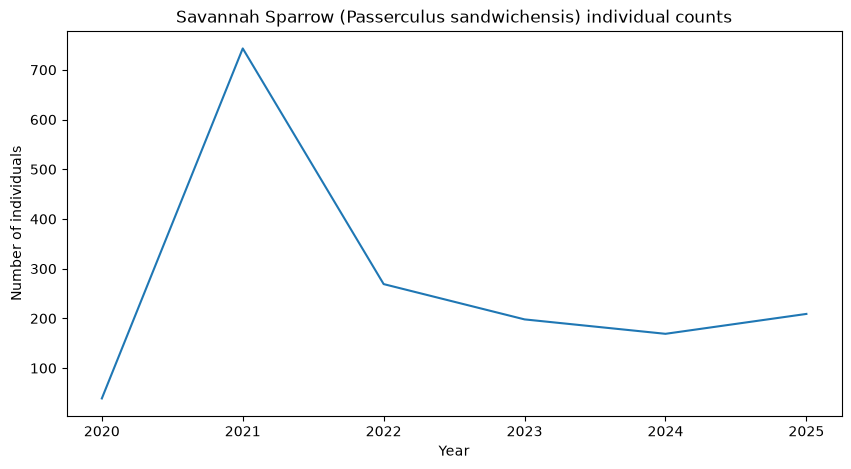

In [14]:
(
    count_df
    .groupby("year")["individualCount"]
    .sum()  # or .mean()
    .plot(
        legend=False,
        xlabel="Year",
        ylabel="Number of individuals",
        figsize=(10, 5),
        title="Savannah Sparrow (Passerculus sandwichensis) individual counts"
    )
)


This chart contradicts my thesis that sightings of Savannah Sparrows would increase over time.
My guess is that the spike in 2021 is because that was the first full year that both parks were open and a lot of people were going. To verify this, I should do an analysis of checklist numbers. Also, the COVID 19 pandemic was still ongoing.

In [15]:
%store gbif_scsp_gdf SCSP_gdf breeding_df breeding_gdf count_df data_dir

Stored 'gbif_scsp_gdf' (GeoDataFrame)
Stored 'SCSP_gdf' (GeoDataFrame)
Stored 'breeding_df' (DataFrame)
Stored 'breeding_gdf' (GeoDataFrame)
Stored 'count_df' (DataFrame)
Stored 'data_dir' (str)
